<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# How far can local Greeks approximate a price move?

Use the real QuantLib-backed worker to price a synthetic European call and calculate its delta and gamma. Then reprice a grid of changed spot prices and compare those results with first- and second-order Taylor approximations built in SQL. The investigation asks how approximation error changes as the shock range widens.

**All inputs are invented model values.** There are no market quotes, transactions or positions. Spot and strike start at 100 quote-currency units, annual volatility is 20%, the continuously compounded annual rate is 3%, and time to expiry is exactly 0.5 years. The worker’s Black–Scholes model assumes no dividend yield. Values are per one underlying unit, with no contract multiplier.

## Choose the spot-shock range

`MAX_MOVE_PCT` is an integer percentage-point extent from **1 to 40**, default **5**. The grid runs from its negative to positive value in **0.5-percentage-point steps**, always including zero. Restart and run all after editing. Time, volatility, rate and strike stay fixed: this is instantaneous model repricing, not a simulated holding period or a dynamically rebalanced hedge.

In [1]:
MAX_MOVE_PCT = 5  # Symmetric spot-shock extent in percent; experiment: 20

In [2]:
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from notebook_support import finish, theme

assert type(MAX_MOVE_PCT) is int and 1 <= MAX_MOVE_PCT <= 40
provenance = json.loads(Path("fixtures/provenance.json").read_text())
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-quant/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-quant/notebooks/pyproject.toml.

## Price the reference option through VGI

The literal `uvx` command pins a remotely available Git revision, its tested SDK and QuantLib 1.44. Every option price and Greek comes from that worker through Haybarn/VGI; Python only presents the returned tables.

The option type is a planning-time constant, so it remains the literal `'call'` in every scalar call. Delta is the first derivative of price with respect to spot; gamma is the second derivative. These are local sensitivities evaluated at the initial spot, not a new fitted curve at each scenario.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'quant' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with QuantLib==1.44 --from git+https://github.com/Query-farm/vgi-quant@5ccb584b8783909bc5383cf514c8905d53f13f6d vgi-quant-worker');
CREATE TABLE inputs AS SELECT 100.0::DOUBLE AS spot,100.0::DOUBLE AS strike,
 0.03::DOUBLE AS rate,0.20::DOUBLE AS vol,0.5::DOUBLE AS ttm;
CREATE TABLE baseline AS SELECT *,
 quant.main.bs_price(spot,strike,rate,vol,ttm,'call') AS call_price,
 quant.main.bs_delta(spot,strike,rate,vol,ttm,'call') AS delta,
 quant.main.bs_gamma(spot,strike,rate,vol,ttm,'call') AS gamma FROM inputs;

,Count


In [4]:
%%sql reference <<
SELECT * FROM baseline;

In [5]:
display(reference)
b = reference.iloc[0]
assert b.spot == provenance["spot"] and b.strike == provenance["strike"]
assert b.rate == provenance["continuous_annual_rate"] and b.vol == provenance["annual_volatility"]
assert b.ttm == provenance["time_to_expiry_years"]
display(
    Markdown(
        f"The reference call price is **{b.call_price:.6f} quote-currency units**. "
        f"Its local delta is **{b.delta:.6f}**, and gamma is **{b.gamma:.6f} per spot-price unit**. "
        "The next step holds these two sensitivities fixed while changing spot."
    )
)

,spot,strike,rate,vol,ttm,call_price,delta,gamma
0,100.0,100.0,0.03,0.2,0.5,6.371028,0.570158,0.027772


The reference call price is **6.371028 quote-currency units**. Its local delta is **0.570158**, and gamma is **0.027772 per spot-price unit**. The next step holds these two sensitivities fixed while changing spot.

## Reprice the grid, then form two approximations

For a spot change ΔS, SQL calculates **delta × ΔS** and **delta × ΔS + ½ × gamma × ΔS²**. Both approximate the *change* in option value; adding the initial price turns them into approximate price levels. Full model repricing supplies the comparison value, not a market-observed truth.

Calls and puts are materialized in **separate statements**, then joined by shock. In the tested published runtime, vectorized call and put invocations of `bs_price` in the same SELECT returned identical call values. Splitting the statements avoids that observed issue; parity below verifies the separated results at every scenario. This is an execution-path limitation, not a property of the pricing model. Implied volatility then inverts each materialized call price; recovering the input volatility checks numerical consistency, not calibration to a market. QuantLib’s inversion defaults to 1e-6 accuracy in standard deviation; dividing by √0.5 converts that to roughly 1.4e-6 in annual volatility, so the check uses a 2e-6 tolerance. The Greek approximations keep the original delta and gamma throughout.

In [6]:
%%sql
CREATE TABLE shocks AS
SELECT i/2.0 AS move_pct FROM range(-{{MAX_MOVE_PCT}}*2,{{MAX_MOVE_PCT}}*2+1) AS r(i);
CREATE TABLE scenarios AS
SELECT s.move_pct,b.*,b.spot*s.move_pct/100 AS spot_change,
 b.spot*(1+s.move_pct/100) AS bumped_spot FROM shocks s CROSS JOIN baseline b;
CREATE TABLE call_prices AS SELECT *,
 quant.main.bs_price(bumped_spot,strike,rate,vol,ttm,'call') AS repriced_call FROM scenarios;
CREATE TABLE put_prices AS SELECT move_pct,
 quant.main.bs_price(bumped_spot,strike,rate,vol,ttm,'put') AS repriced_put FROM scenarios;
CREATE TABLE repriced AS SELECT c.*,p.repriced_put FROM call_prices c JOIN put_prices p USING(move_pct);
CREATE TABLE compared AS SELECT *,
 repriced_call-call_price AS exact_change,
 delta*spot_change AS delta_change,
 delta*spot_change+0.5*gamma*spot_change*spot_change AS delta_gamma_change,
 quant.main.implied_vol(repriced_call,bumped_spot,strike,rate,ttm,'call') AS recovered_vol FROM repriced;
CREATE TABLE errors AS SELECT *,delta_change-exact_change AS delta_error,
 delta_gamma_change-exact_change AS delta_gamma_error FROM compared;

,Count


In [7]:
%%sql curve <<
SELECT move_pct,bumped_spot,repriced_call,exact_change,delta_change,delta_gamma_change,
 delta_error,delta_gamma_error,recovered_vol FROM errors ORDER BY move_pct;

,move_pct,bumped_spot,repriced_call,exact_change,delta_change,delta_gamma_change,delta_error,delta_gamma_error,recovered_vol
0,-5.0,95.0,3.877017,-2.494011,-2.850791,-2.503639,-0.356779,-0.009628,0.2
10,0.0,100.0,6.371028,0.000000,0.000000,0.000000,0.000000,0.000000,0.2
20,5.0,105.0,9.553211,3.182183,2.850791,3.197942,-0.331393,0.015759,0.2


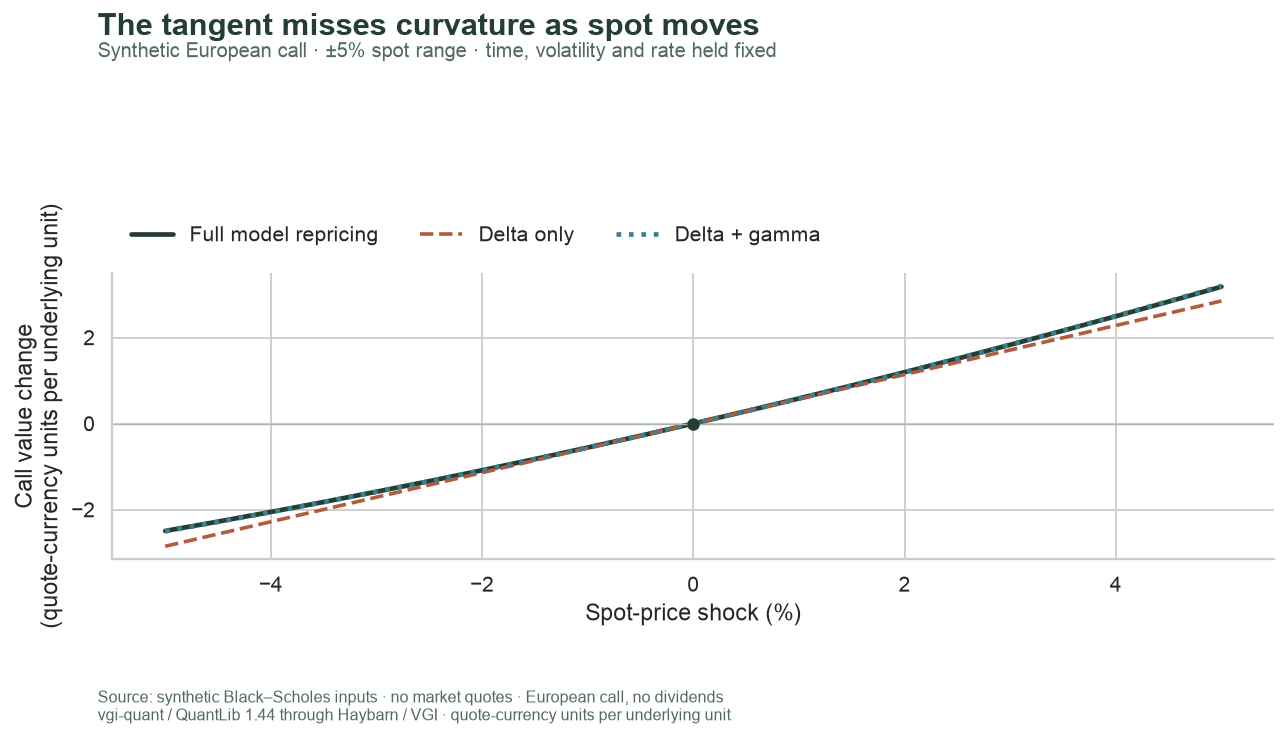

In [8]:
display(curve.loc[curve.move_pct.isin([-MAX_MOVE_PCT, 0, MAX_MOVE_PCT])])
fig, ax = plt.subplots(figsize=(10.5, 5.7))
ax.plot(curve.move_pct, curve.exact_change, color="#243e32", linewidth=2.6, label="Full model repricing")
ax.plot(curve.move_pct, curve.delta_change, "--", color="#b25b3f", linewidth=2, label="Delta only")
ax.plot(curve.move_pct, curve.delta_gamma_change, ":", color="#397f91", linewidth=2.6, label="Delta + gamma")
ax.scatter([0], [0], color="#243e32", s=35, zorder=5)
ax.axhline(0, color="#aab6b0", linewidth=0.8)
ax.set(xlabel="Spot-price shock (%)", ylabel="Call value change\n(quote-currency units per underlying unit)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.03), ncol=3, frameon=False)
finish(
    fig,
    f"repricing-{MAX_MOVE_PCT}",
    "The tangent misses curvature as spot moves",
    f"Synthetic European call · ±{MAX_MOVE_PCT}% spot range · time, volatility and rate held fixed",
)

## Measure the approximation error directly

The chart below uses **approximation minus full model change**. Positive values overstate the model change; negative values understate it. The y-axis uses quote-currency units, avoiding unstable percentage errors near the zero-change scenario. Gamma can improve a local approximation, but omitted higher-order terms still matter as the shock grows. We measure the result rather than require the quadratic approximation to win everywhere.

In [9]:
%%sql diagnostics <<
SELECT count(*) AS scenarios,
 max(abs(delta_error)) AS max_delta_error,
 max(abs(delta_gamma_error)) AS max_delta_gamma_error,
 count(*) FILTER(WHERE move_pct<>0 AND abs(delta_gamma_error)<abs(delta_error)) AS gamma_better,
 count(*) FILTER(WHERE move_pct<>0) AS nonzero_scenarios,
 max(abs(recovered_vol-vol)) AS max_vol_roundtrip_error,
 max(abs(repriced_call-repriced_put-(bumped_spot-strike*exp(-rate*ttm)))) AS max_parity_error
FROM errors;

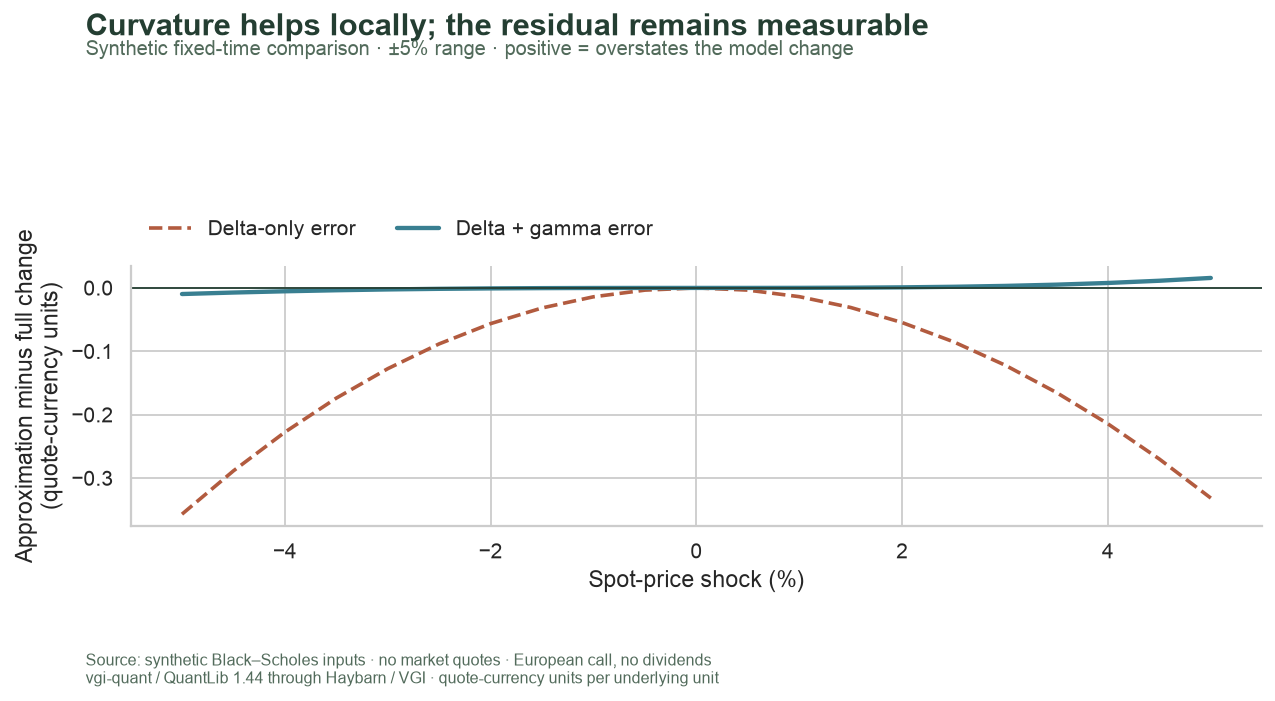

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.plot(curve.move_pct, curve.delta_error, "--", color="#b25b3f", linewidth=2, label="Delta-only error")
ax.plot(curve.move_pct, curve.delta_gamma_error, color="#397f91", linewidth=2.4, label="Delta + gamma error")
ax.axhline(0, color="#243e32", linewidth=1)
ax.set(xlabel="Spot-price shock (%)", ylabel="Approximation minus full change\n(quote-currency units)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.03), ncol=2, frameon=False)
finish(
    fig,
    f"errors-{MAX_MOVE_PCT}",
    "Curvature helps locally; the residual remains measurable",
    f"Synthetic fixed-time comparison · ±{MAX_MOVE_PCT}% range · positive = overstates the model change",
)

In [11]:
display(diagnostics)
d = diagnostics.iloc[0]
display(
    Markdown(
        f"Across **{int(d.scenarios)} scenarios**, the maximum absolute error is "
        f"**{d.max_delta_error:.6f}** for delta alone and **{d.max_delta_gamma_error:.6f}** for delta + gamma "
        "(quote-currency units per underlying unit). The quadratic term reduces absolute error in "
        f"**{int(d.gamma_better)} of {int(d.nonzero_scenarios)} nonzero scenarios**. "
        f"The largest volatility round-trip residual is **{d.max_vol_roundtrip_error:.2e}** "
        "in annual volatility units; "
        f"the largest put–call parity residual is **{d.max_parity_error:.2e}** in price units. "
        "These checks establish internal model consistency, not realistic market behavior or hedge profitability."
    )
)

,scenarios,max_delta_error,max_delta_gamma_error,gamma_better,nonzero_scenarios,max_vol_roundtrip_error,max_parity_error
0,21,0.356779,0.015759,20,20,9.319005e-07,2.486900e-14


Across **21 scenarios**, the maximum absolute error is **0.356779** for delta alone and **0.015759** for delta + gamma (quote-currency units per underlying unit). The quadratic term reduces absolute error in **20 of 20 nonzero scenarios**. The largest volatility round-trip residual is **9.32e-07** in annual volatility units; the largest put–call parity residual is **2.49e-14** in price units. These checks establish internal model consistency, not realistic market behavior or hedge profitability.

## Verify the local Greeks independently of the wide grid

A separate **0.01-price-unit** symmetric bump checks the analytic delta and gamma with central finite differences: `(C(S+h)−C(S−h))/(2h)` and `(C(S+h)−2C(S)+C(S−h))/h²`. The small bump remains fixed when the main grid widens. A separate one-year textbook anchor (spot=strike=100, rate 5%, volatility 20%) checks call ≈10.4506 and put ≈5.5735 within 5e-5 price units. Floating-point checks use tolerances; the zero-shock row must reconcile to the baseline. Positive spot and time inputs are validated before calls because this worker raises on invalid non-NULL inputs.

In [12]:
%%sql
CREATE TABLE textbook_call AS SELECT quant.main.bs_price(100,100,0.05,0.2,1,'call') AS price;
CREATE TABLE textbook_put AS SELECT quant.main.bs_price(100,100,0.05,0.2,1,'put') AS price;
CREATE TABLE local_probe AS SELECT b.*,0.01::DOUBLE AS h,
 quant.main.bs_price(spot+0.01,strike,rate,vol,ttm,'call') AS plus_price,
 quant.main.bs_price(spot-0.01,strike,rate,vol,ttm,'call') AS minus_price FROM baseline b;
CREATE TABLE local_differences AS SELECT delta,gamma,
 (plus_price-minus_price)/(2*h) AS finite_delta,
 (plus_price-2*call_price+minus_price)/(h*h) AS finite_gamma FROM local_probe;

,Count


In [13]:
%%sql local <<
SELECT *,abs(delta-finite_delta) AS delta_difference,abs(gamma-finite_gamma) AS gamma_difference
FROM local_differences;

In [14]:
display(local)

,delta,gamma,finite_delta,finite_gamma,delta_difference,gamma_difference
0,0.570158,0.027772,0.570158,0.027772,1.041418e-08,8.071704e-10


In [15]:
%%sql checks <<
SELECT 'scenario grid has unique shocks and expected size' AS check_name,
 (SELECT count(*)=count(DISTINCT move_pct) AND count(*)=4*{{MAX_MOVE_PCT}}+1 FROM errors) AS passed
UNION ALL SELECT 'grid spans selected extent in half-percent steps',
 (SELECT min(move_pct)=-{{MAX_MOVE_PCT}} AND max(move_pct)={{MAX_MOVE_PCT}}
 AND bool_and(abs(move_pct*2-round(move_pct*2))<1e-12) FROM errors)
UNION ALL SELECT 'spot and maturity remain positive',(SELECT bool_and(bumped_spot>0 AND ttm>0) FROM errors)
UNION ALL SELECT 'prices and sensitivities are finite',
 (SELECT bool_and(isfinite(repriced_call) AND isfinite(repriced_put) AND isfinite(delta) AND isfinite(gamma)) FROM errors)
UNION ALL SELECT 'call prices obey model bounds',
 (SELECT bool_and(repriced_call>=greatest(bumped_spot-strike*exp(-rate*ttm),0)-1e-10
 AND repriced_call<=bumped_spot+1e-10) FROM errors)
UNION ALL SELECT 'zero shock agrees with baseline',
 (SELECT abs(exact_change)<1e-10 AND abs(delta_change)<1e-10 AND abs(delta_gamma_change)<1e-10 FROM errors WHERE move_pct=0)
UNION ALL SELECT 'put-call parity holds',(SELECT max(abs(repriced_call-repriced_put-(bumped_spot-strike*exp(-rate*ttm))))<1e-8 FROM errors)
UNION ALL SELECT 'implied volatility round-trips',(SELECT max(abs(recovered_vol-vol))<2e-6 FROM errors)
UNION ALL SELECT 'textbook one-year call and put anchors',
 (SELECT abs(c.price-10.4506)<5e-5 AND abs(p.price-5.5735)<5e-5 FROM textbook_call c CROSS JOIN textbook_put p)
UNION ALL SELECT 'analytic delta agrees with small bump',(SELECT abs(delta-finite_delta)<1e-6 FROM local_differences)
UNION ALL SELECT 'analytic gamma agrees with small bump',(SELECT abs(gamma-finite_gamma)<1e-6 FROM local_differences)
UNION ALL SELECT 'reference call delta and gamma have valid signs',(SELECT delta BETWEEN 0 AND 1 AND gamma>0 FROM baseline)
UNION ALL SELECT 'repriced calls rise with spot',
 (SELECT bool_and(previous IS NULL OR repriced_call>=previous-1e-10)
 FROM(SELECT *,lag(repriced_call) OVER(ORDER BY bumped_spot) AS previous FROM errors));

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
display(Markdown(f"**{len(checks)} numerical and structural SQL checks passed.**"))

,check_name,passed
0,scenario grid has unique shocks and expected size,True
1,grid spans selected extent in half-percent steps,True
2,spot and maturity remain positive,True
3,prices and sensitivities are finite,True
4,call prices obey model bounds,True
5,zero shock agrees with baseline,True
6,put-call parity holds,True
7,implied volatility round-trips,True
8,textbook one-year call and put anchors,True
9,analytic delta agrees with small bump,True


**13 numerical and structural SQL checks passed.**

## Focused experiment: widen the range

Change only **`MAX_MOVE_PCT` from 5 to 20**, restart and run all. Predict larger maximum approximation errors, while the baseline price/Greeks and the small-bump verification stay unchanged. Compare the residual chart and result-derived error summary. The grid keeps its 0.5-percentage-point spacing and adds more distant shocks.

Full repricing remains exact only within this particular no-dividend Black–Scholes model. The experiment includes no time decay, changing volatility, transaction costs or discrete rebalancing; it cannot establish a profitable hedge. Restore **5** for the saved baseline. The README command executes the wider range into a separate copy.

In [17]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>